# **Machine y Deep Learning**

# **Unidad 4**

## **Proyecto Unidad 4**

### **Docente:** Jose Gabriel Rodriguez Rivas

### **Alumnos:**

Antonio Manuel Aldama Gandara

Alejandro Herrera Gracia

Jesús Aarón Retana Suárez

Juan David Zuñiga Herrera

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [ ]:
redes = pd.read_csv("Students Social Network Profile.csv")
redes.head()

,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,...,0,0,0,3,0,0,0,0,0,0


###**Estandarización de los datos**

In [ ]:
features = ['basketball','football','soccer','softball','volleyball','swimming',
'cheerleading','baseball','tennis','sports','cute','sex','sexy','hot','kissed',
'dance','band','marching','music','rock','god','church','jesus','bible','hair',
'dress','blonde','mall','shopping','clothes','hollister','abercrombie',
'die','death','drunk','drugs','NumberOffriends']
X = redes[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#K-Means 10 PCs
pca10 = PCA(n_components=10, random_state=42)
X_pca10 = pca10.fit_transform(X_scaled)

# Graficar 2 PCs
pca2 = PCA(n_components=2, random_state=42)
X_pca = pca2.fit_transform(X_scaled)

###**Análisis de Componentes Principales (PCA)**

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_
print("Proporción de varianza explicada por cada componente:", explained_variance)
print("Varianza explicada acumulada:", np.cumsum(explained_variance))

Proporción de varianza explicada por cada componente: [0.09087236 0.04851737]
Varianza explicada acumulada: [0.09087236 0.13938972]


###**Aplicación de K-Means**

k=2 | Inercia=202585 | Silhouette=0.4745
k=3 | Inercia=188174 | Silhouette=0.3585
k=4 | Inercia=175035 | Silhouette=0.3637
k=5 | Inercia=163222 | Silhouette=0.3491
k=6 | Inercia=153319 | Silhouette=0.3422
k=7 | Inercia=143632 | Silhouette=0.3202
k=8 | Inercia=134042 | Silhouette=0.3183
k=9 | Inercia=127663 | Silhouette=0.3149
k=10 | Inercia=121931 | Silhouette=0.3172
    k      Inercia  Silhouette
0   2  202584.8114      0.4745
1   3  188173.5107      0.3585
2   4  175034.9973      0.3637
3   5  163221.5122      0.3491
4   6  153318.6925      0.3422
5   7  143631.7051      0.3202
6   8  134042.3626      0.3183
7   9  127662.8704      0.3149
8  10  121931.1897      0.3172


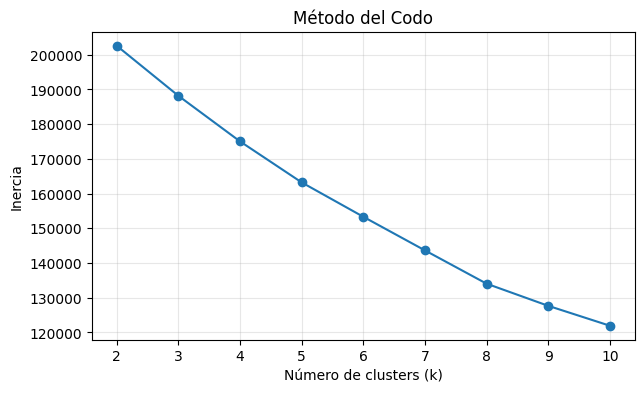

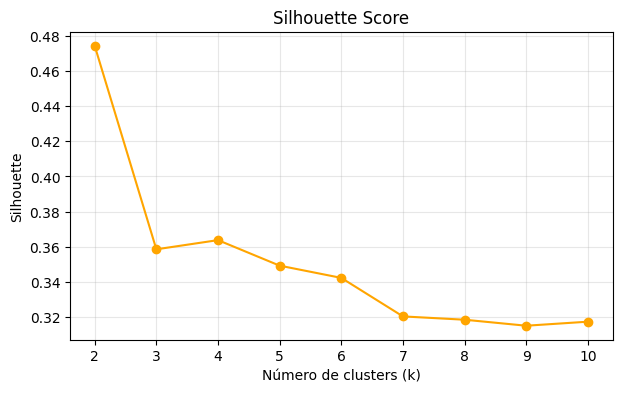

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca10)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_pca10, labels)
    silhouettes.append(sil)
    print(f"k={k} | Inercia={km.inertia_:.0f} | Silhouette={sil:.4f}")

# Tabla para tu reporte
import pandas as pd
tabla_k = pd.DataFrame({
    'k': list(K_range),
    'Inercia': inertias,
    'Silhouette': silhouettes
})
print(tabla_k.round(4))

# Gráfico del Codo
plt.figure(figsize=(7,4))
plt.plot(K_range, inertias, marker='o')
plt.title("Método del Codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(alpha=0.3)
plt.show()

# Gráfico Silhouette
plt.figure(figsize=(7,4))
plt.plot(K_range, silhouettes, marker='o', color='orange')
plt.title("Silhouette Score")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette")
plt.grid(alpha=0.3)
plt.show()


###**Visualización**

cluster
0    10438
1      537
2      449
3      339
4     3237
Name: count, dtype: int64
Varianza PC1-PC4: [0.09087236 0.04851737 0.04511857 0.04166068]
Varianza acumulada PC1-PC4: 0.22616896830249605


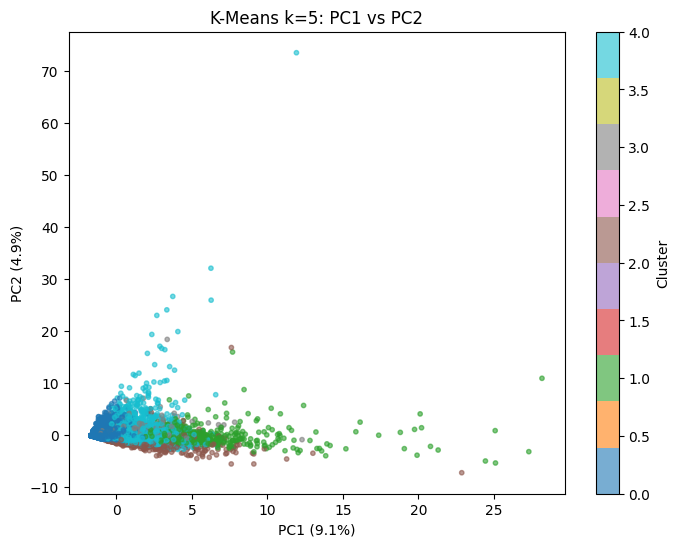

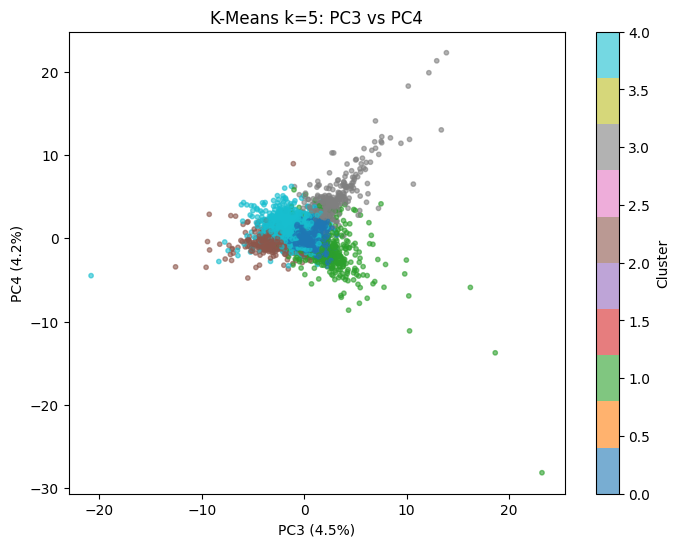

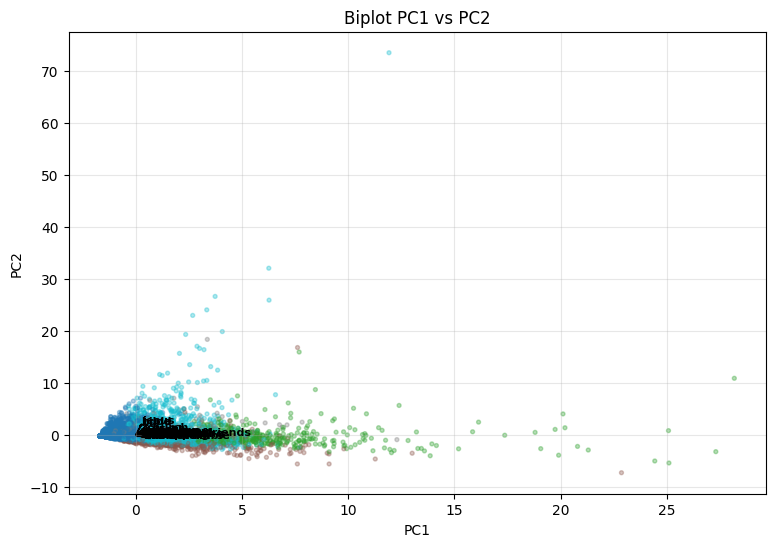

In [ ]:
kmeans_final = KMeans(n_clusters=5, n_init=10, random_state=42)
redes['cluster'] = kmeans_final.fit_predict(X_pca10)

print(redes['cluster'].value_counts().sort_index())

pca4 = PCA(n_components=4, random_state=42)
X_pca4 = pca4.fit_transform(X_scaled)
print("Varianza PC1-PC4:", pca4.explained_variance_ratio_)
print("Varianza acumulada PC1-PC4:", pca4.explained_variance_ratio_.sum())

# PC1 vs PC2
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=redes['cluster'], cmap='tab10', s=10, alpha=0.6)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("K-Means k=5: PC1 vs PC2")
plt.colorbar(label='Cluster')
plt.show()

# PC3 vs PC4
plt.figure(figsize=(8,6))
plt.scatter(X_pca4[:,2], X_pca4[:,3], c=redes['cluster'], cmap='tab10', s=10, alpha=0.6)
plt.xlabel(f"PC3 ({pca4.explained_variance_ratio_[2]*100:.1f}%)")
plt.ylabel(f"PC4 ({pca4.explained_variance_ratio_[3]*100:.1f}%)")
plt.title("K-Means k=5: PC3 vs PC4")
plt.colorbar(label='Cluster')
plt.show()

# Biplot PC1 vs PC2
plt.figure(figsize=(9,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=redes['cluster'], cmap='tab10', s=8, alpha=0.35)
for i, feat in enumerate(features):
    plt.arrow(0, 0, pca2.components_[0,i]*4, pca2.components_[1,i]*4,
              color='black', head_width=0.12, length_includes_head=True)
    plt.text(pca2.components_[0,i]*4.2, pca2.components_[1,i]*4.2,
             feat, fontsize=8, fontweight='bold')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Biplot PC1 vs PC2")
plt.grid(alpha=0.3)
plt.show()

###**Interpretación de resultados**

In [ ]:
print("=== Promedio por cluster ===")
print(redes.groupby('cluster')[features].mean().round(2).T)

print("\n=== Amigos y conteo ===")
print(redes.groupby('cluster')['NumberOffriends'].mean().round(1))
print(redes['cluster'].value_counts().sort_index())

print("\n=== Género por cluster (%) ===")
print(pd.crosstab(redes['cluster'], redes['gender'], normalize='index').round(2))

print("\n=== Año de graduación promedio ===")
print(redes.groupby('cluster')['gradyear'].mean().round(2))

=== Promedio por cluster ===
cluster              0      1      2      3      4
basketball        0.13   0.59   0.40   0.18   0.65
football          0.13   0.53   0.39   0.30   0.61
soccer            0.12   0.38   0.29   0.16   0.52
softball          0.07   0.26   0.15   0.19   0.44
volleyball        0.06   0.20   0.26   0.12   0.37
swimming          0.08   0.27   0.26   0.17   0.28
cheerleading      0.05   0.22   0.35   0.06   0.24
baseball          0.05   0.22   0.14   0.05   0.27
tennis            0.05   0.14   0.13   0.21   0.18
sports            0.07   0.55   0.19   0.09   0.30
cute              0.17   0.85   0.64   0.32   0.71
sex               0.10   2.55   0.27   0.23   0.19
sexy              0.09   0.42   0.22   0.17   0.22
hot               0.07   0.22   0.38   0.12   0.27
kissed            0.03   1.55   0.14   0.10   0.09
dance             0.24   1.11   0.63   0.52   0.90
band              0.15   0.73   0.17   5.07   0.23
marching          0.01   0.04   0.01   1.40   0.01
mu

**Deportistas:** Ideales para campañas de torneos, activación física y liderazgo estudiantil. Son los más conectados.

**Fiesteros:** Grupo de riesgo. Se recomienda campañas de bienestar, consumo responsable y acompañamiento, no castigo. Son pocos (3.8%) pero muy visibles.

**Religiosos:** Grupo de apoyo comunitario. Ideales para voluntariado, mentoría y actividades de servicio.

**Introvertidos:** La mayoría (71%). No es que no tengan intereses, es que no los expresan en el perfil. Necesitan espacios de baja presión: clubes de música, lectura, arte.

###**Conclusiones**

El análisis de los 15,000 perfiles demuestra que los estudiantes sí se agrupan por intereses, pero la mayoría no es visible. El 69.6% pertenece al cluster introvertido, mientras que el resto se reparte entre sociables, fiesteros, moda y banda. El clustering no busca etiquetar, sino entender para diseñar mejores estrategias de convivencia y bienestar.

La varianza de PC1 y PC2 es baja porque los datos tienen muchos ceros y son muy dispersos. Los clusters se solapan en la gráfica, lo cual es normal en datos sociales. El dataset es de 2006-2009 y no se puede generalizar a redes actuales sin actualizar datos.